# 05_Baseline_Models — TF-IDF Grid & Selection on Validation

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
grid = pd.read_csv('reports/phase3b/grid_results.csv')
best = pd.read_csv('reports/phase3b/best_by_variant.csv')
mm = json.load(open('models/MANIFEST_models.json', encoding='utf-8'))
print(f'Grid fits: {len(grid)} | scikit-learn {mm["_sklearn"]} | test set not used in this step')

Grid fits: 24 | scikit-learn 1.6.1 | test set not used in this step


## 1. Grid Results (validation)

In [4]:
print(grid[['variant', 'model', 'C', 'class_weight', 'val_macro_f1', 'val_accuracy', 'val_top2_accuracy',
            'val_min_recall', 'fit_seconds']].to_string(index=False))

       variant      model    C class_weight  val_macro_f1  val_accuracy  val_top2_accuracy  val_min_recall  fit_seconds
         as_is     logreg  1.0         none        0.8377        0.8487             0.9553          0.6755        136.6
         as_is     logreg  1.0     balanced        0.8428        0.8499             0.9550          0.7835        119.8
         as_is     logreg  4.0         none        0.8397        0.8502             0.9559          0.6926        180.9
         as_is     logreg  4.0     balanced        0.8436        0.8517             0.9571          0.7643        175.8
         as_is     logreg 16.0         none        0.8383        0.8485             0.9555          0.6899        219.1
         as_is     logreg 16.0     balanced        0.8399        0.8487             0.9562          0.7391        218.4
         as_is linear_svc  0.1         none        0.8417        0.8519             0.9531          0.6899          7.1
         as_is linear_svc  0.1     balan

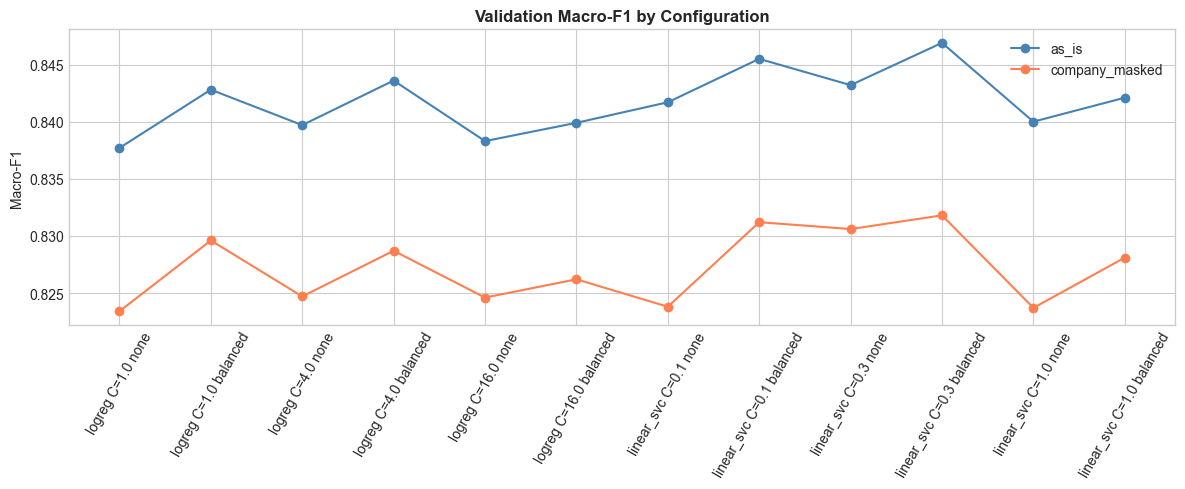

✓ Saved: 05_grid_macro_f1.png


In [5]:
grid['config'] = grid['model'] + ' C=' + grid['C'].astype(str) + ' ' + grid['class_weight']
fig, ax = plt.subplots(figsize=(12, 5))
for v, color in [('as_is', 'steelblue'), ('company_masked', 'coral')]:
    d = grid[grid['variant'] == v]
    ax.plot(d['config'], d['val_macro_f1'], marker='o', label=v, color=color)
ax.set_title('Validation Macro-F1 by Configuration', fontsize=12, fontweight='bold')
ax.set_ylabel('Macro-F1'); ax.tick_params(axis='x', rotation=60); ax.legend()
plt.tight_layout()
plt.savefig('output/05_grid_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_grid_macro_f1.png')

## 2. Selected Models

In [6]:
print(best.to_string(index=False))
gap = best.set_index('variant').loc['as_is', 'val_macro_f1'] - best.set_index('variant').loc['company_masked', 'val_macro_f1']
print(f'\nMacro-F1 gap (as_is − company_masked, val): {gap:+.4f}')

       variant      model   C class_weight  calibrated_on_val  val_macro_f1  val_accuracy  val_top2_accuracy  val_min_recall
         as_is linear_svc 0.3     balanced               True        0.8469        0.8550             0.9541          0.7616
company_masked linear_svc 0.3     balanced               True        0.8318        0.8425             0.9478          0.7281

Macro-F1 gap (as_is − company_masked, val): +0.0151


## 3. Recall by Service (validation, selected models)

variant                    as_is  company_masked
Comptes & Dépôts          0.8131          0.7974
Crédit immobilier         0.9193          0.9030
Crédits aux particuliers  0.8654          0.8430
Monétique                 0.8206          0.8092
Recouvrement              0.9153          0.9159
Transferts & Paiements    0.7616          0.7281


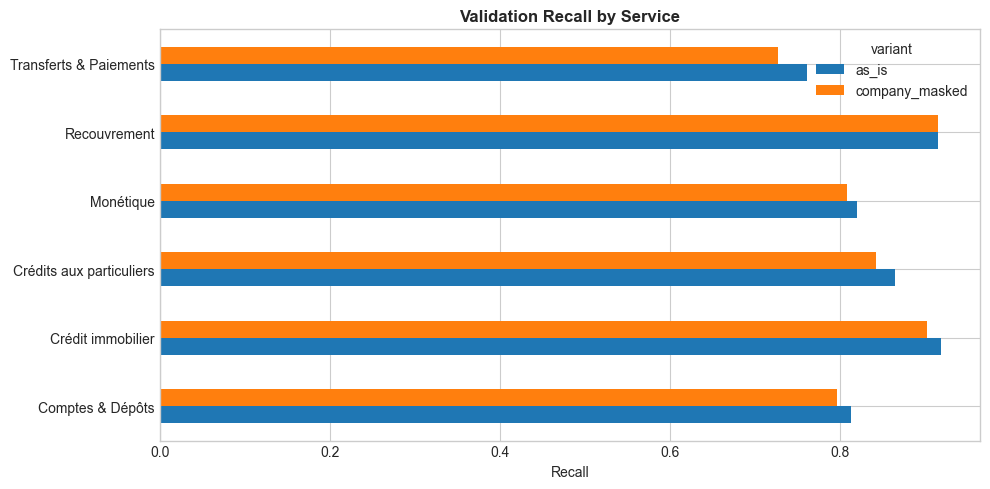

✓ Saved: 05_val_recall_by_service.png


In [7]:
rec = grid.loc[grid.groupby('variant')['val_macro_f1'].idxmax()].set_index('variant')
rec = rec[[c for c in rec.columns if c.startswith('recall_')]].T
rec.index = rec.index.str.replace('recall_', '')
print(rec.round(4).to_string())
ax = rec.plot.barh(figsize=(10, 5))
ax.set_title('Validation Recall by Service', fontsize=12, fontweight='bold'); ax.set_xlabel('Recall')
plt.tight_layout()
plt.savefig('output/05_val_recall_by_service.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_val_recall_by_service.png')

## 4. Validation Confusion Matrix — company_masked

                          Comptes & Dépôts  Crédit immobilier  Crédits aux particuliers  Monétique  Recouvrement  Transferts & Paiements
Comptes & Dépôts                      2599                  5                        34        207            55                     294
Crédit immobilier                       18               1049                        58         19            19                       2
Crédits aux particuliers                63                 12                      1757        106           186                      16
Monétique                              269                  3                        71       2665           171                      71
Recouvrement                            47                 32                       144        116          4382                      11
Transferts & Paiements                 362                  6                        13         87            16                     980


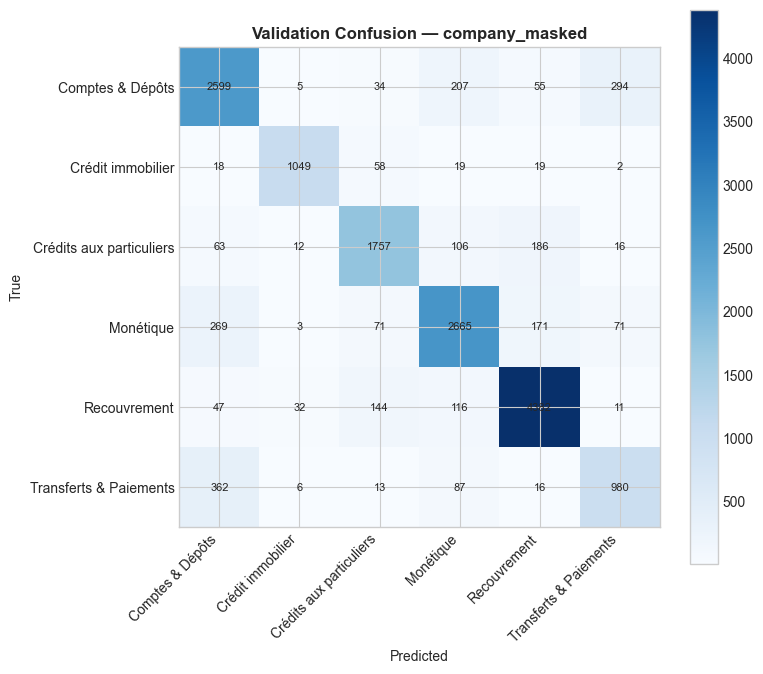

✓ Saved: 05_val_confusion_company_masked.png


In [8]:
cm = pd.read_csv('reports/phase3b/confusion_val_company_masked.csv', index_col=0)
print(cm.to_string())
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm.values, cmap='Blues')
ax.set_xticks(range(len(cm)), cm.columns, rotation=45, ha='right'); ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, cm.values[i, j], ha='center', va='center', fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); fig.colorbar(im, ax=ax)
ax.set_title('Validation Confusion — company_masked', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/05_val_confusion_company_masked.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_val_confusion_company_masked.png')